<a href="https://colab.research.google.com/github/MLILA05/COU07506-labs/blob/main/COU07506_Week04_240242422800.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 4 — z-Transform Laboratory
## Poles, Zeros and Stability

- Name:DAUDI MUSA MLILA
- Registration number: 240242422800
- Date:7
- Group:240242422800

## Pre-lab

### (a) Find the poles and check stability

The transfer function is

$$
H(z)=\frac{1}{1-0.9z^{-1}+0.81z^{-2}}.
$$

To find the poles, set the denominator equal to zero.

$$
1-0.9z^{-1}+0.81z^{-2}=0.
$$

Multiplying every term by $z^2$ gives

$$
z^2-0.9z+0.81=0.
$$

Using the quadratic formula with $a=1$, $b=-0.9$, and $c=0.81$,

$$
z = \frac{0.9 \pm \sqrt{(-0.9)^2 - 4(1)(0.81)}}{2}
  = \frac{0.9 \pm \sqrt{-2.43}}{2}.
$$

Since $\sqrt{-2.43}=j\sqrt{2.43}$, the two poles are

$$
p_1 \approx 0.45 + j0.7794,\qquad
p_2 \approx 0.45 - j0.7794.
$$

The magnitude of each pole is

$$
|p_1|=|p_2|=\sqrt{(0.45)^2+\left(\frac{\sqrt{2.43}}{2}\right)^2}
=\sqrt{0.81}=0.9.
$$

Both poles lie inside the unit circle because $0.9<1$.
Therefore, the causal system is BIBO stable.


### (b) Partial-fraction expansion

$$
X(z)=\frac{1}{(1-0.5z^{-1})(1-0.25z^{-1})}
=\frac{A}{1-0.5z^{-1}}+\frac{B}{1-0.25z^{-1}}.
$$

Multiplying both sides by $(1-0.5z^{-1})(1-0.25z^{-1})$ gives

$$
1=A(1-0.25z^{-1})+B(1-0.5z^{-1}).
$$


Expanding the brackets and grouping like terms gives

$$
1=(A+B)+(-0.25A-0.5B)z^{-1}.
$$

The left side has a constant of $1$ and a coefficient of $0$ for $z^{-1}$.
Matching the coefficients gives

$$
A+B=1,
\qquad
-0.25A-0.5B=0.
$$


Dividing $-0.25A-0.5B=0$ by $-0.25$ gives

$$
A+2B=0.
$$

Subtracting $A+B=1$ from $A+2B=0$ gives $B=-1$.
Substituting into $A+B=1$ gives $A=2$.

Therefore, the partial-fraction expansion is

$$
X(z)=\frac{2}{1-0.5z^{-1}}-\frac{1}{1-0.25z^{-1}}.
$$

## Task 4.1 — Pole-zero plot

Zeros: [-1.  0.]
Poles: [0.5  0.25]
Causal system is stable: True


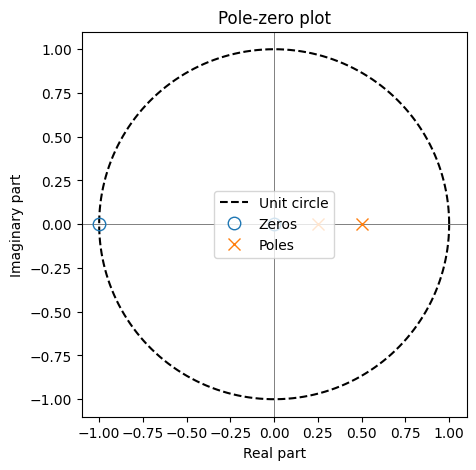

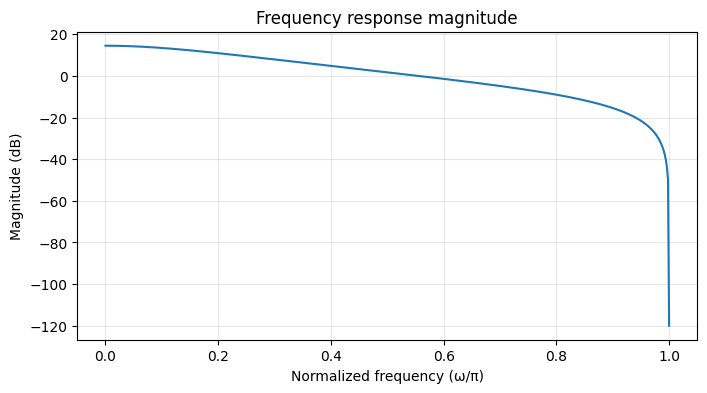

DC gain: 5.333333
Nyquist gain: 0.000000


In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

b = [1, 1]
a = [1, -0.75, 0.125]

# Multiply the numerator and denominator by z² for tf2zpk.
zeros, poles, gain = signal.tf2zpk([1, 1, 0], a)

print("Zeros:", zeros)
print("Poles:", poles)
print("Causal system is stable:", np.all(np.abs(poles) < 1))

theta = np.linspace(0, 2 * np.pi, 400)
fig, ax = plt.subplots(figsize=(5, 5))

ax.plot(np.cos(theta), np.sin(theta), "k--", label="Unit circle")
ax.axhline(0, color="gray", linewidth=0.7)
ax.axvline(0, color="gray", linewidth=0.7)

ax.plot(zeros.real, zeros.imag, "o",
        markerfacecolor="none", markersize=9, label="Zeros")
ax.plot(poles.real, poles.imag, "x", markersize=9, label="Poles")

ax.set_title("Pole-zero plot")
ax.set_xlabel("Real part")
ax.set_ylabel("Imaginary part")
ax.set_aspect("equal")
ax.legend()
plt.show()

# Include both endpoints so we can check DC and the Nyquist frequency.
omega = np.linspace(0, np.pi, 513)
omega, response = signal.freqz(b, a, worN=omega)

magnitude = np.abs(response)
magnitude_db = 20 * np.log10(np.maximum(magnitude, 1e-6))

plt.figure(figsize=(8, 4))
plt.plot(omega / np.pi, magnitude_db)
plt.title("Frequency response magnitude")
plt.xlabel("Normalized frequency (ω/π)")
plt.ylabel("Magnitude (dB)")
plt.grid(alpha=0.3)
plt.show()

print(f"DC gain: {magnitude[0]:.6f}")
print(f"Nyquist gain: {magnitude[-1]:.6f}")

## Task 4.2 — Inverse z-transform with residuez

In [29]:
residues, poles_pf, direct_terms = signal.residuez([1], a)

for residue, pole in zip(residues, poles_pf):
    print(f"Pole = {pole:.2f}, residue = {residue:.2f}")

    n = np.arange(10)

# Reconstruct the sequence from the residue-pole pairs.
x_from_residues = sum(
    residue * pole**n
    for residue, pole in zip(residues, poles_pf)
)

# Compare with the filter's response to a unit impulse.
impulse = np.zeros(10)
impulse[0] = 1
x_from_filter = signal.lfilter([1], a, impulse)

print("From residues:", np.round(x_from_residues, 6))
print("From lfilter: ", np.round(x_from_filter, 6))
print("All 10 samples match:", np.allclose(x_from_residues, x_from_filter))

residues_h, poles_h, _ = signal.residuez(b, a)

for residue, pole in zip(residues_h, poles_h):
    print(f"Pole = {pole:.2f}, residue = {residue:.2f}")

h_from_residues = sum(
    residue * pole**n
    for residue, pole in zip(residues_h, poles_h)
)
h_from_filter = signal.lfilter(b, a, impulse)
h_expected = 6 * 0.5**n - 5 * 0.25**n

print("From residues:", np.round(h_from_residues, 6))
print("Matches lfilter:", np.allclose(h_from_residues, h_from_filter))
print("Matches Week 3 formula:", np.allclose(h_from_residues, h_expected))

Pole = 0.25, residue = -1.00
Pole = 0.50, residue = 2.00
From residues: [1.       0.75     0.4375   0.234375 0.121094 0.061523 0.031006 0.015564
 0.007797 0.003902]
From lfilter:  [1.       0.75     0.4375   0.234375 0.121094 0.061523 0.031006 0.015564
 0.007797 0.003902]
All 10 samples match: True
Pole = 0.25, residue = -5.00
Pole = 0.50, residue = 6.00
From residues: [1.       1.75     1.1875   0.671875 0.355469 0.182617 0.092529 0.04657
 0.023361 0.0117  ]
Matches lfilter: True
Matches Week 3 formula: True


## Task 4.3 — Pole position and the impulse response

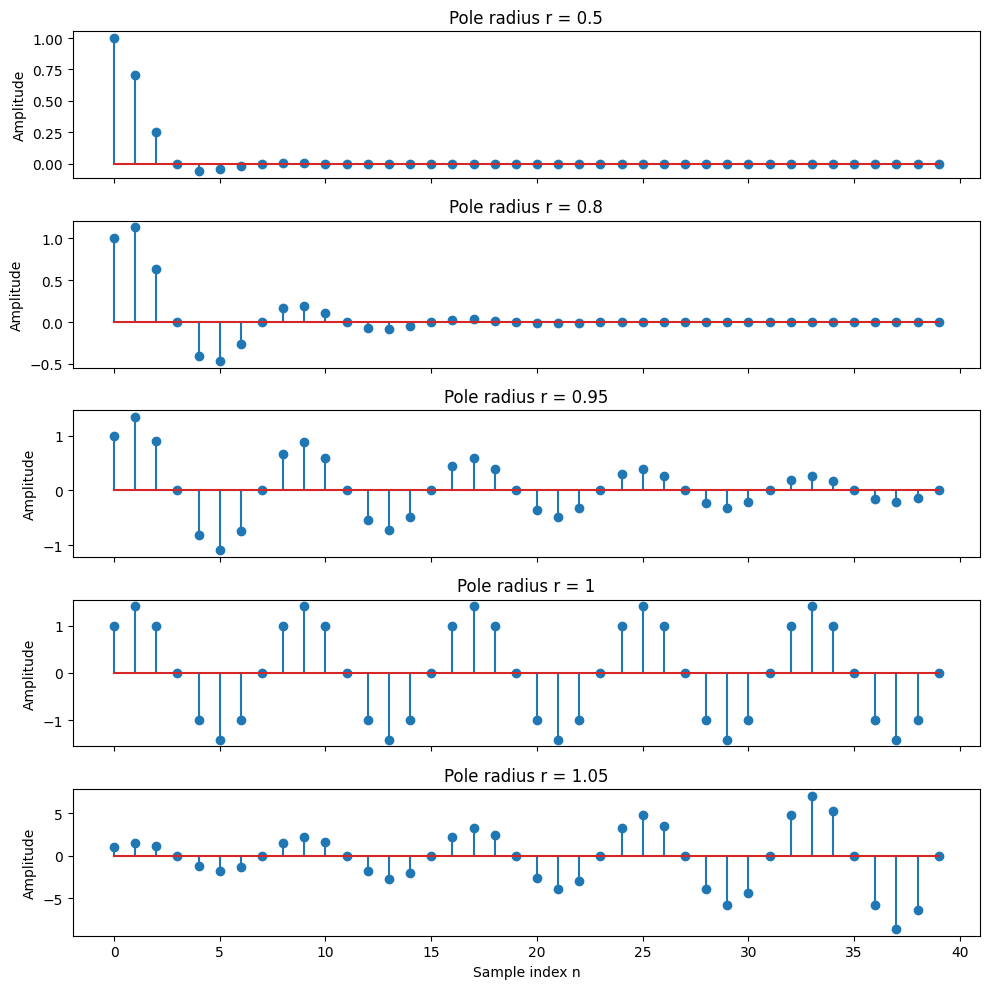

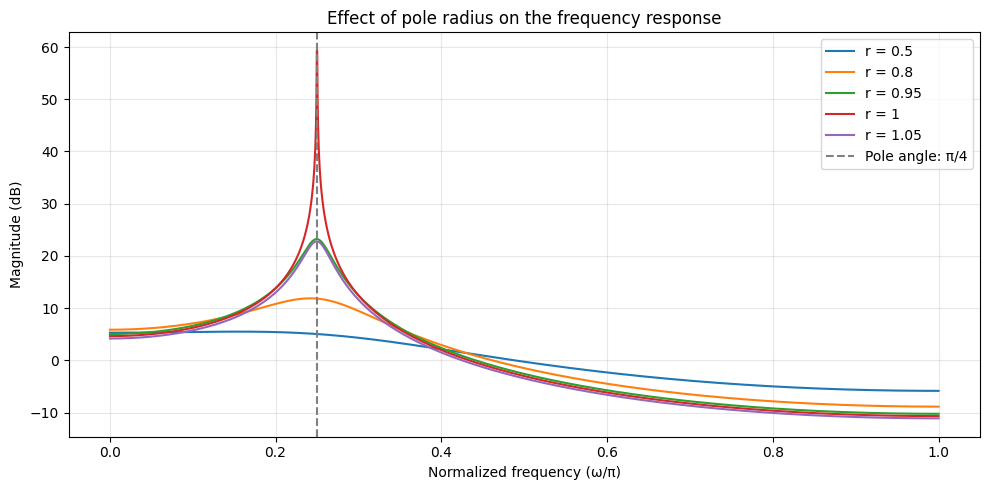

In [30]:
radii = [0.5, 0.8, 0.95, 1.0, 1.05]
pole_angle = np.pi / 4
n_response = np.arange(40)

impulse_40 = np.zeros(40)
impulse_40[0] = 1

fig, axes = plt.subplots(5, 1, figsize=(10, 10), sharex=True)

for ax, radius in zip(axes, radii):
    denominator = [1, -2 * radius * np.cos(pole_angle), radius**2]
    impulse_response = signal.lfilter([1], denominator, impulse_40)

    ax.stem(n_response, impulse_response)
    ax.set_title(f"Pole radius r = {radius:g}")
    ax.set_ylabel("Amplitude")

axes[-1].set_xlabel("Sample index n")
plt.tight_layout()
plt.show()

# Use a frequency grid that avoids the exact pole at ω = π/4 for r = 1.
omega_grid = (np.arange(2048) + 0.5) * np.pi / 2048

plt.figure(figsize=(10, 5))

for radius in radii:
    denominator = [1, -2 * radius * np.cos(pole_angle), radius**2]
    omega, response = signal.freqz([1], denominator, worN=omega_grid)
    magnitude_db = 20 * np.log10(np.abs(response))

    plt.plot(omega / np.pi, magnitude_db, label=f"r = {radius:g}")

plt.axvline(0.25, color="gray", linestyle="--", label="Pole angle: π/4")
plt.title("Effect of pole radius on the frequency response")
plt.xlabel("Normalized frequency (ω/π)")
plt.ylabel("Magnitude (dB)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



### Observation

For $r=0.5$, $0.8$, and $0.95$, the impulse response decays.
As $r$ gets closer to 1, it decays more slowly and the resonance
near $\omega/\pi=0.25$ becomes sharper. The pole angle stays
at $\pi/4$, so the oscillation repeats every 8 samples.

At $r=1$, the oscillation persists without decay, so the causal
system is not BIBO stable. The tall peak in the plot shows values
near the pole. The response is singular at the exact pole frequency.

At $r=1.05$, the oscillations grow because the poles are outside
the unit circle. This causal system is also unstable.

## Task 4.4 — Stability of given systems

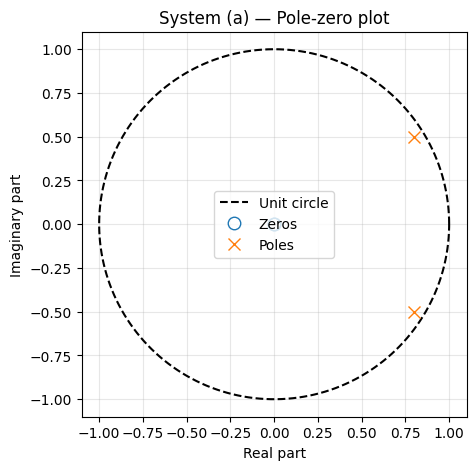

Poles: [0.8+0.5j 0.8-0.5j]
Pole magnitudes: [0.9434 0.9434]
Causal system is stable: True


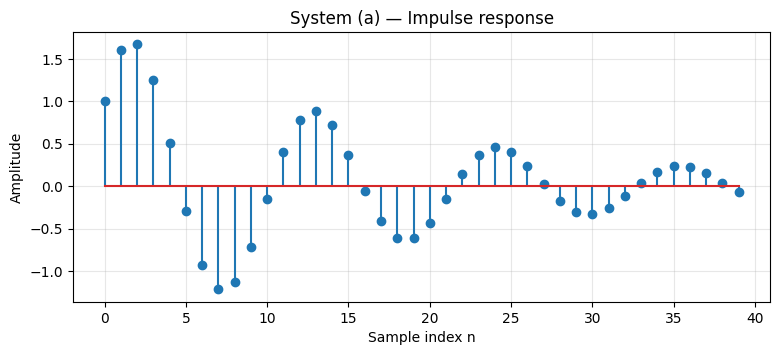

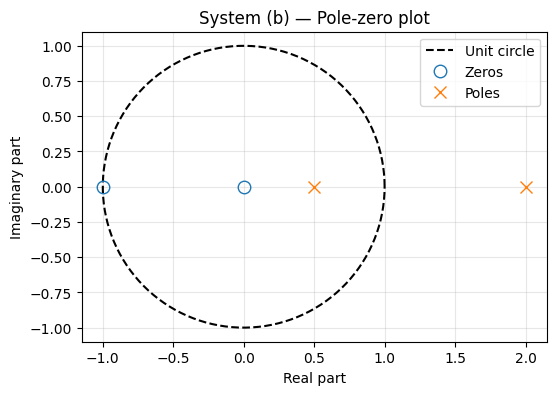

Poles: [2.  0.5]
Pole magnitudes: [2.  0.5]
Causal system is stable: False


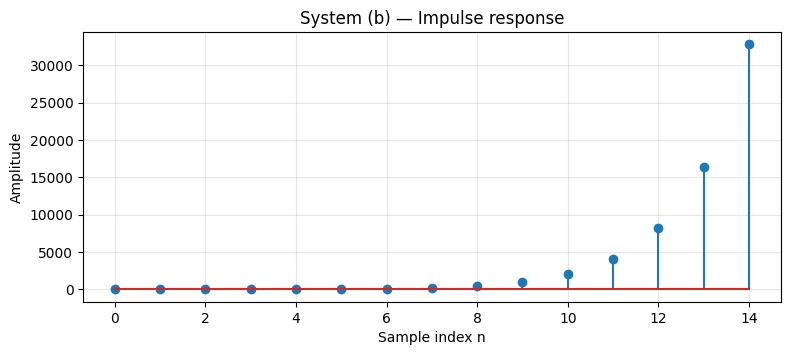

First five samples: [ 1.      3.5     7.75   15.875  31.9375]


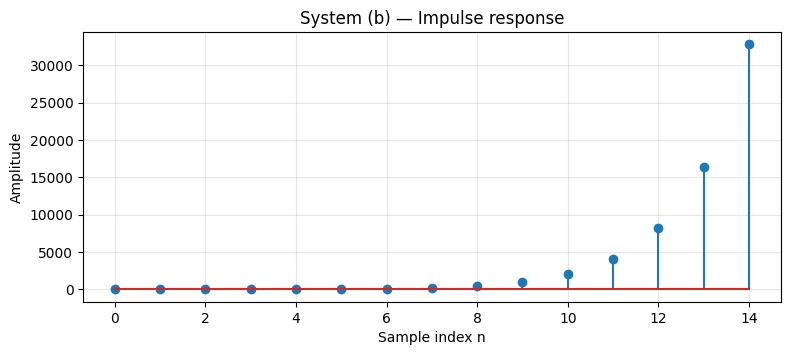

First five samples: [ 1.      3.5     7.75   15.875  31.9375]


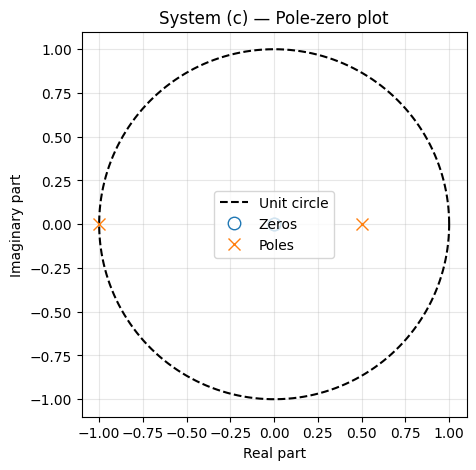

System (c) poles: [-1.   0.5]
Pole magnitudes: [1.  0.5]
Causal system is stable: False


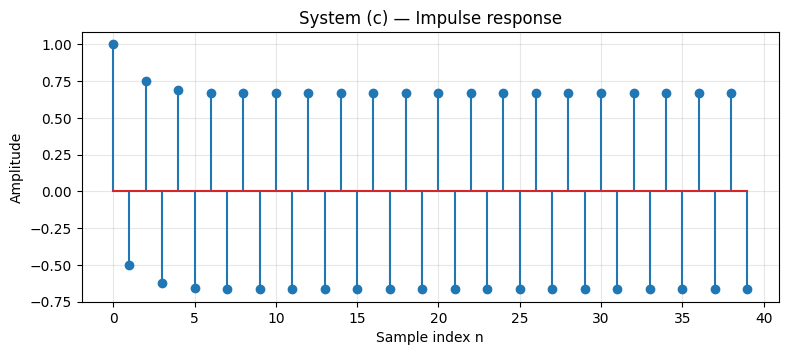

Last six samples: [ 0.6667 -0.6667  0.6667 -0.6667  0.6667 -0.6667]


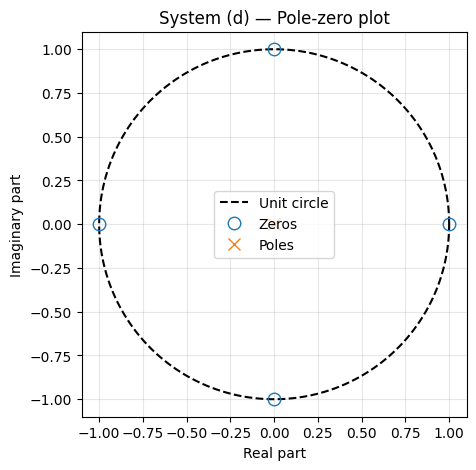

System (d) zeros: [-1.+0.j  0.+1.j  0.-1.j  1.+0.j]
System (d) poles: [0. 0. 0. 0.]
Causal system is stable: True


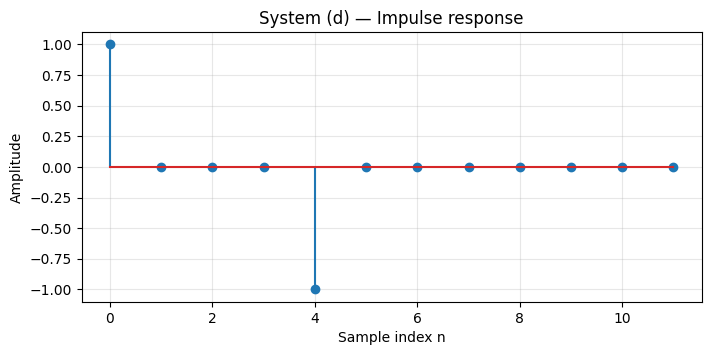

First eight samples: [ 1.  0.  0.  0. -1.  0.  0.  0.]


In [31]:
def zplane(b, a, ax):
    # Give both polynomials the same degree before finding their roots.
    length = max(len(b), len(a))
    b_poly = np.pad(b, (0, length - len(b)))
    a_poly = np.pad(a, (0, length - len(a)))
    zeros, poles, _ = signal.tf2zpk(b_poly, a_poly)

    theta = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(theta), np.sin(theta), "k--", label="Unit circle")
    ax.plot(zeros.real, zeros.imag, "o", mfc="none", ms=9, label="Zeros")
    ax.plot(poles.real, poles.imag, "x", ms=9, label="Poles")
    ax.set_xlabel("Real part")
    ax.set_ylabel("Imaginary part")
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.legend()
    return zeros, poles

b1 = [1]
a1 = [1, -1.6, 0.89]

fig, ax = plt.subplots(figsize=(5, 5))
zeros1, poles1 = zplane(b1, a1, ax)
ax.set_title("System (a) — Pole-zero plot")
plt.show()

print("Poles:", poles1)
print("Pole magnitudes:", np.round(np.abs(poles1), 4))
print("Causal system is stable:", np.all(np.abs(poles1) < 1))
h1 = signal.lfilter(b1, a1, impulse_40)

plt.figure(figsize=(9, 3.5))
plt.stem(n_response, h1)
plt.title("System (a) — Impulse response")
plt.xlabel("Sample index n")
plt.ylabel("Amplitude")
plt.grid(alpha=0.3)
plt.show()

b2 = [1, 1]
a2 = [1, -2.5, 1]

fig, ax = plt.subplots(figsize=(6, 5))
zeros2, poles2 = zplane(b2, a2, ax)
ax.set_title("System (b) — Pole-zero plot")
plt.show()

print("Poles:", poles2)
print("Pole magnitudes:", np.abs(poles2))
print("Causal system is stable:", np.all(np.abs(poles2) < 1))
h2 = signal.lfilter(b2, a2, impulse_40)

plt.figure(figsize=(9, 3.5))
plt.stem(n_response[:15], h2[:15])
plt.title("System (b) — Impulse response")
plt.xlabel("Sample index n")
plt.ylabel("Amplitude")
plt.grid(alpha=0.3)
plt.show()

print("First five samples:", h2[:5])
h2 = signal.lfilter(b2, a2, impulse_40)

plt.figure(figsize=(9, 3.5))
plt.stem(n_response[:15], h2[:15])
plt.title("System (b) — Impulse response")
plt.xlabel("Sample index n")
plt.ylabel("Amplitude")
plt.grid(alpha=0.3)
plt.show()

print("First five samples:", h2[:5])
b3 = [1]
a3 = [1, 0.5, -0.5]

fig, ax = plt.subplots(figsize=(5, 5))
zeros3, poles3 = zplane(b3, a3, ax)
ax.set_title("System (c) — Pole-zero plot")
plt.show()

print("System (c) poles:", poles3)
print("Pole magnitudes:", np.abs(poles3))
print("Causal system is stable:", np.all(np.abs(poles3) < 1))
h3 = signal.lfilter(b3, a3, impulse_40)

plt.figure(figsize=(9, 3.5))
plt.stem(n_response, h3)
plt.title("System (c) — Impulse response")
plt.xlabel("Sample index n")
plt.ylabel("Amplitude")
plt.grid(alpha=0.3)
plt.show()

print("Last six samples:", np.round(h3[-6:], 4))
b4 = [1, 0, 0, 0, -1]
a4 = [1]

fig, ax = plt.subplots(figsize=(5, 5))
zeros4, poles4 = zplane(b4, a4, ax)
ax.set_title("System (d) — Pole-zero plot")
plt.show()

print("System (d) zeros:", np.round(zeros4, 4))
print("System (d) poles:", poles4)
print("Causal system is stable:", np.all(np.abs(poles4) < 1))

h4 = signal.lfilter(b4, a4, impulse_40)

plt.figure(figsize=(8, 3.5))
plt.stem(n_response[:12], h4[:12])
plt.title("System (d) — Impulse response")
plt.xlabel("Sample index n")
plt.ylabel("Amplitude")
plt.grid(alpha=0.3)
plt.show()

print("First eight samples:", h4[:8])

### Task 4.4 — Stability summary

| System | Pole magnitudes | Causal BIBO stability | Impulse response |
|---|---|---|---|
| (a) | 0.9434, 0.9434 | Stable | Oscillates and decays toward zero. |
| (b) | 2, 0.5 | Unstable | Grows because of the pole at $z=2$. |
| (c) | 1, 0.5 | Unstable | Alternates without decaying because of the pole at $z=-1$. |
| (d) | 0 (four poles) | Stable | Has two nonzero samples, at $n=0$ and $n=4$. |

## Task 4.5 — Design a resonator

### Step 1 — Calculate the pole angle

The target frequency is $f_0=1000$ Hz and the sampling rate is
$f_s=8000$ Hz. The pole radius is $r=0.97$.

$$
\theta = 2\pi\frac{f_0}{f_s}
       = 2\pi\frac{1000}{8000}
       = \frac{\pi}{4}
       \text{ radians per sample}.
$$

fs_resonator = 8000
target_frequency = 1000
r_resonator = 0.97

theta_resonator = 2 * np.pi * target_frequency / fs_resonator

a_resonator = [
    1,
    -2 * r_resonator * np.cos(theta_resonator),
    r_resonator**2,
]

print("Denominator coefficients:", np.round(a_resonator, 6))



Denominator coefficients: [ 1.       -1.371787  0.9409  ]


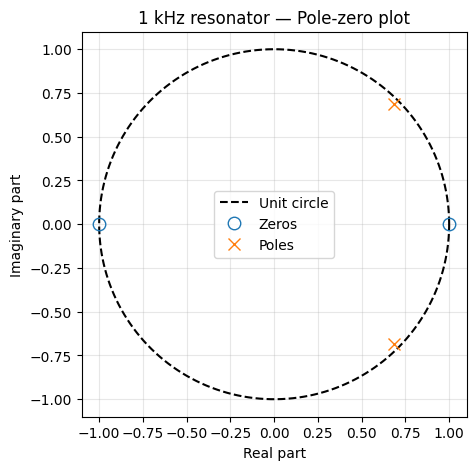

Zeros: [-1.  1.]
Pole magnitudes: [0.97 0.97]


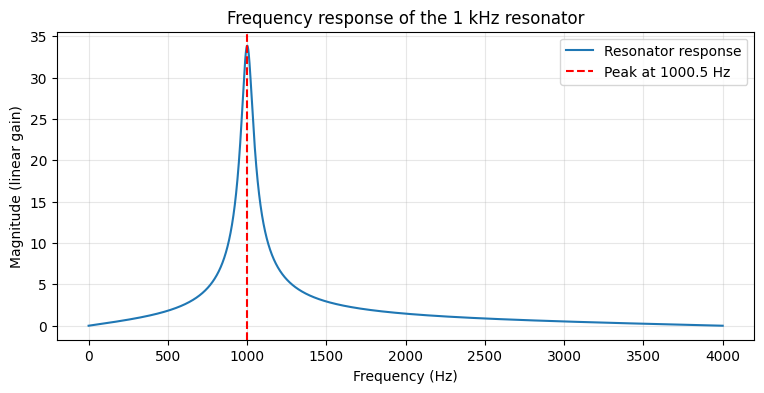

Peak frequency: 1000.5 Hz
Gain at 0 Hz: 0.000000
Gain at 4000 Hz: 0.000000
Original white noise


White noise after the 1 kHz resonator


In [32]:
fs_resonator = 8000
target_frequency = 1000
r_resonator = 0.97

theta_resonator = 2 * np.pi * target_frequency / fs_resonator
a_resonator = [
    1,
    -2 * r_resonator * np.cos(theta_resonator),
    r_resonator**2,
]

print("Denominator coefficients:", np.round(a_resonator, 6))

b_resonator = [1, 0, -1]

fig, ax = plt.subplots(figsize=(5, 5))
zeros_resonator, poles_resonator = zplane(b_resonator, a_resonator, ax)
ax.set_title("1 kHz resonator — Pole-zero plot")
plt.show()

print("Zeros:", zeros_resonator)
print("Pole magnitudes:", np.round(np.abs(poles_resonator), 4))
frequency_grid = np.linspace(0, fs_resonator / 2, 8001)

frequency_hz, response = signal.freqz(
    b_resonator, a_resonator, worN=frequency_grid, fs=fs_resonator
)

magnitude = np.abs(response)
peak_frequency = frequency_hz[np.argmax(magnitude)]

plt.figure(figsize=(9, 4))
plt.plot(frequency_hz, magnitude, label="Resonator response")
plt.axvline(peak_frequency, color="red", linestyle="--",
            label=f"Peak at {peak_frequency:.1f} Hz")
plt.title("Frequency response of the 1 kHz resonator")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (linear gain)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

print(f"Peak frequency: {peak_frequency:.1f} Hz")
print(f"Gain at 0 Hz: {magnitude[0]:.6f}")
print(f"Gain at 4000 Hz: {magnitude[-1]:.6f}")

from IPython.display import Audio, display

rng = np.random.default_rng(0)
white_noise = rng.standard_normal(3 * fs_resonator)
filtered_noise = signal.lfilter(b_resonator, a_resonator, white_noise)

print("Original white noise")
display(Audio(white_noise, rate=fs_resonator))

print("White noise after the 1 kHz resonator")
display(Audio(filtered_noise, rate=fs_resonator))

## Analysis Answers

### 1. How does the pole radius affect the resonance bandwidth?

In Task 4.3, increasing the pole radius $r$ toward 1 made the
resonance peak narrower. The peak for $r=0.95$ was narrower
than the peak for $r=0.8$ because the poles were closer to the
unit circle. A narrower peak means the filter emphasizes a
smaller range of frequencies.

The impulse response also took longer to decay at $r=0.95$
than at $r=0.8$.


### 2. What happens to the impulse response when a pole lies on the unit circle?

A pole on the unit circle has magnitude $1$, so its contribution to
the impulse response does not decay. In System (c), the pole at
$z=-1$ produces a term proportional to $(-1)^n$. This makes the
response alternate between approximately $+0.6667$ and $-0.6667$
after the decaying part becomes small.

The sum of the absolute values of the impulse response is infinite,
so the causal system is not BIBO stable.

### 3. Why do zeros at $z=\pm1$ make the resonator a band-pass filter?

The zero at $z=1$ blocks DC ($0$ Hz), and the zero at $z=-1$
blocks the Nyquist frequency ($4000$ Hz). The pole pair creates
a strong peak between those endpoints, near $1000$ Hz.

In my plot, the gain was zero at both endpoints and peaked at
$1000.5$ Hz. The filter therefore emphasizes a band around
$1000$ Hz while suppressing frequencies near DC and Nyquist.





### 4. Check Systems (a)–(c) using the stability triangle

For a second-order denominator $A(z)=1+a_1z^{-1}+a_2z^{-2}$,
a causal system is stable if all three of these expressions
are strictly positive:

$$
1+a_1+a_2>0,\qquad 1-a_1+a_2>0,\qquad 1-a_2>0.
$$

| System | $a_1$ | $a_2$ | $1+a_1+a_2$ | $1-a_1+a_2$ | $1-a_2$ | Result |
|---|---:|---:|---:|---:|---:|---|
| (a) | -1.60 | 0.89 | 0.29 | 3.49 | 0.11 | Stable |
| (b) | -2.50 | 1.00 | -0.50 | 4.50 | 0.00 | Unstable |
| (c) | 0.50 | -0.50 | 1.00 | 0.00 | 1.50 | Unstable |

System (a) is inside the stability triangle because all three
values are positive. System (b) is outside because the first
value is negative. System (c) is on the boundary because
$1-a_1+a_2=0$, which corresponds to its pole at $z=-1$.
The triangle test agrees with my pole-zero plots.



## AI-use statement

I used ChatGPT to explain the z-transform calculations and help write
and troubleshoot the Python code. I checked my partial fractions
against SciPy, compared the reconstructed impulse responses with
`lfilter`, and verified the stability results using the stability
triangle.